# FTWP Chapter 5 — Review and Exercises

This notebook consolidates the **six non-capstone tasks** for FTWP Chapter 5:
three review exercises and three regular exercises. The problem statements are
paraphrased from the CPF exercise sheet. Numerical parameters are stated where
the source task leaves them open.

The notebook is designed to run from top to bottom in Google Colab or a standard
Python/Jupyter environment.

In [1]:
%matplotlib inline

## Review exercises

### 1. A simulated payoff vector in a large discrete state space

Each simulated terminal stock value is one component of a payoff vector
$S_T\in\mathbb R^{|\Omega|}$.

### 2. Moments and the probability vector

For state probabilities $P$, $E_P[S_T]=P^\top S_T$. With equally weighted
Monte Carlo states, $p_i=1/I$.

### 3. Rank and completeness

For a payoff matrix $M$, completeness requires $\operatorname{rank}(M)=|\Omega|$.
With thousands of simulated states and only a bond and stock, the market is
highly incomplete.

Payoff-vector dimension: (2000,)
Probability sum: 1.0000000000000004
E_P[ST]: 104.43268689340225
SD_P[ST]: 21.222626470575143
rank([bond, stock]): 2
Number of states: 2000


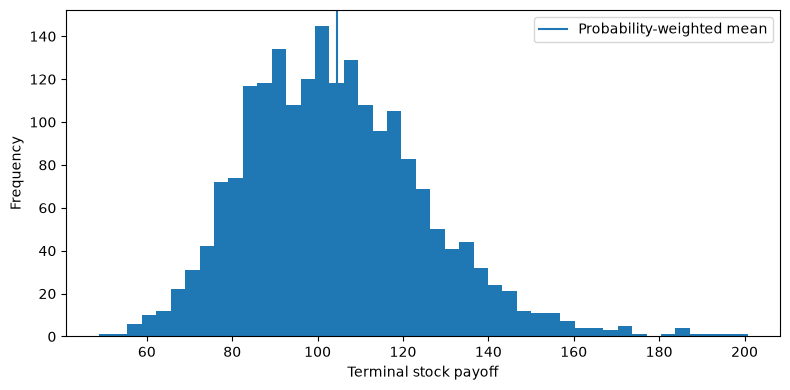

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.random import default_rng
from scipy.optimize import brentq
from scipy.stats import norm

S0, K, r, sigma, T = 100.0, 105.0, 0.05, 0.20, 1.0
I_review = 2_000
rng = default_rng(2026)

Z_review = rng.standard_normal(I_review)
ST_review = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z_review)
P_review = np.full(I_review, 1.0 / I_review)

mean_ST = P_review @ ST_review
variance_ST = P_review @ (ST_review - mean_ST) ** 2
sd_ST = math.sqrt(variance_ST)

BT_review = np.full(I_review, 100.0 * math.exp(r * T))
M_review = np.column_stack((BT_review, ST_review))
rank_review = np.linalg.matrix_rank(M_review)

print("Payoff-vector dimension:", ST_review.shape)
print("Probability sum:", P_review.sum())
print("E_P[ST]:", mean_ST)
print("SD_P[ST]:", sd_ST)
print("rank([bond, stock]):", rank_review)
print("Number of states:", I_review)

plt.figure(figsize=(8, 4))
plt.hist(ST_review, bins=45)
plt.axvline(mean_ST, label="Probability-weighted mean")
plt.xlabel("Terminal stock payoff")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## Regular exercises

### 4. Compute a martingale measure numerically

For a finite set of positive terminal stock payoffs, I construct strictly
positive weights

$$Q_i(\lambda)=\frac{e^{\lambda S_{T,i}}}{\sum_j e^{\lambda S_{T,j}}}$$

and choose $\lambda$ numerically so that

$$E_Q[S_T]=S_0e^{rT}.$$

This enforces nonnegativity, sum-to-one, and the discounted stock-pricing
restriction. It selects one measure from many possible martingale measures.

In [3]:
I_q = 500
rng_q = default_rng(17)
ST_q = S0 * np.exp((0.02 - 0.5 * 0.25**2) * T + 0.25 * math.sqrt(T) * rng_q.standard_normal(I_q))
target_mean = S0 * math.exp(r * T)

def tilted_weights(lam, values):
    scaled = lam * values
    scaled -= scaled.max()
    w = np.exp(scaled)
    return w / w.sum()

def martingale_error(lam):
    q = tilted_weights(lam, ST_q)
    return q @ ST_q - target_mean

lam_star = brentq(martingale_error, -2.0, 2.0)
Q = tilted_weights(lam_star, ST_q)

B0 = 100.0
BT = B0 * math.exp(r * T)
bond_price_check = math.exp(-r * T) * (Q @ np.full(I_q, BT))
stock_price_check = math.exp(-r * T) * (Q @ ST_q)

print("lambda:", lam_star)
print("sum(Q):", Q.sum())
print("min(Q):", Q.min())
print("E_Q[ST]:", Q @ ST_q)
print("Discounted bond price:", bond_price_check)
print("Discounted stock price:", stock_price_check)

lambda: 0.005926104621109165
sum(Q): 1.0
min(Q): 0.00146174453679945
E_Q[ST]: 105.12710963760239
Discounted bond price: 100.00000000000001
Discounted stock price: 99.99999999999999


### 5. European option pricing under GBM

Simulate risk-neutral GBM terminal values, discount the call payoff, and compare
with Black-Scholes.

### 6. Jump diffusion and approximate replication

Compare GBM with a Merton-style jump diffusion. The risk-neutral drift includes
the compensator $-\lambda_J\kappa_J$, where
$\kappa_J=E[e^Y-1]$. For each model, regress the call payoff on terminal bond
and stock payoffs and compare residual RMSE.

GBM Monte Carlo call: 8.113083310449477
Monte Carlo SE: 0.05911523053908908
Black-Scholes call: 8.021352235143176
Difference: 0.09173107530630098
GBM hedge holdings: [-0.50387432  0.58397415]
Jump hedge holdings: [-0.47148072  0.5760887 ]


,Mean ST,SD ST,Discounted call price,Static-hedge RMSE
Model,,,,
GBM,105.312711,21.229249,8.113083,6.277933
Jump diffusion,105.446477,28.373910,10.635808,8.750970


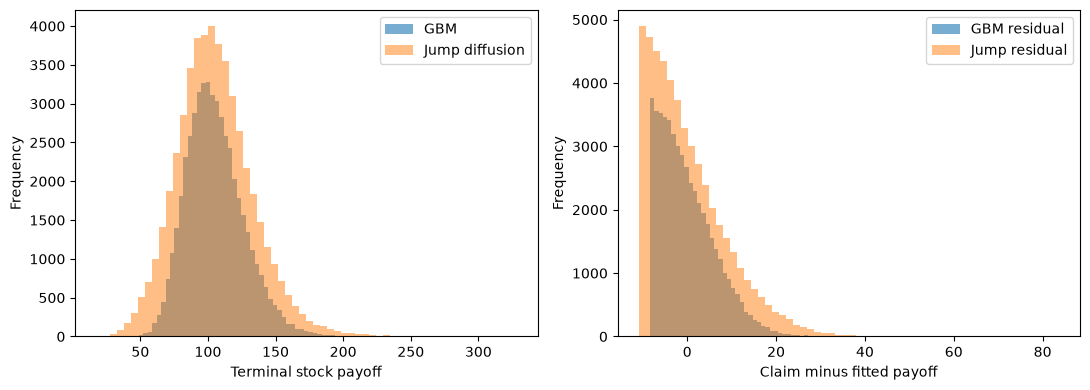

In [4]:
I = 50_000
seed = 100
rng = default_rng(seed)
Z = rng.standard_normal(I)

ST_gbm = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z)
call_gbm = np.maximum(ST_gbm - K, 0.0)
discount = math.exp(-r * T)
mc_price = discount * call_gbm.mean()
mc_se = discount * call_gbm.std(ddof=1) / math.sqrt(I)

d1 = (math.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * math.sqrt(T))
d2 = d1 - sigma * math.sqrt(T)
bs_price = S0 * norm.cdf(d1) - K * discount * norm.cdf(d2)

# Jump-diffusion parameters and simulation.
lambda_j = 0.75
mu_j = -0.10
sigma_j = 0.20
kappa_j = math.exp(mu_j + 0.5 * sigma_j**2) - 1.0
rng_jump = default_rng(seed)
Z_jump = rng_jump.standard_normal(I)
N_jump = rng_jump.poisson(lambda_j * T, I)
jump_sum = np.where(
    N_jump > 0,
    N_jump * mu_j + np.sqrt(N_jump) * sigma_j * rng_jump.standard_normal(I),
    0.0,
)
ST_jump = S0 * np.exp(
    (r - lambda_j * kappa_j - 0.5 * sigma**2) * T
    + sigma * math.sqrt(T) * Z_jump
    + jump_sum
)
call_jump = np.maximum(ST_jump - K, 0.0)

def static_hedge(ST, claim):
    bond_payoff = np.full_like(ST, 100.0 * math.exp(r * T))
    A = np.column_stack((bond_payoff, ST))
    phi, *_ = np.linalg.lstsq(A, claim, rcond=None)
    residual = claim - A @ phi
    return phi, residual, math.sqrt(np.mean(residual**2))

phi_gbm, residual_gbm, rmse_gbm = static_hedge(ST_gbm, call_gbm)
phi_jump, residual_jump, rmse_jump = static_hedge(ST_jump, call_jump)

comparison = pd.DataFrame(
    {
        "Model": ["GBM", "Jump diffusion"],
        "Mean ST": [ST_gbm.mean(), ST_jump.mean()],
        "SD ST": [ST_gbm.std(ddof=1), ST_jump.std(ddof=1)],
        "Discounted call price": [discount * call_gbm.mean(), discount * call_jump.mean()],
        "Static-hedge RMSE": [rmse_gbm, rmse_jump],
    }
).set_index("Model")

print("GBM Monte Carlo call:", mc_price)
print("Monte Carlo SE:", mc_se)
print("Black-Scholes call:", bs_price)
print("Difference:", mc_price - bs_price)
print("GBM hedge holdings:", phi_gbm)
print("Jump hedge holdings:", phi_jump)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(ST_gbm, bins=60, alpha=0.6, label="GBM")
axes[0].hist(ST_jump, bins=60, alpha=0.5, label="Jump diffusion")
axes[0].set_xlabel("Terminal stock payoff")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[1].hist(residual_gbm, bins=60, alpha=0.6, label="GBM residual")
axes[1].hist(residual_jump, bins=60, alpha=0.5, label="Jump residual")
axes[1].set_xlabel("Claim minus fitted payoff")
axes[1].set_ylabel("Frequency")
axes[1].legend()
plt.tight_layout()
plt.show()

The jump model changes the terminal distribution and the shape of the option
payoff sample. Because a static bond-stock payoff is linear in $S_T$ while the
call is kinked, residual risk remains in both models and can change materially
when jumps alter tail behavior.

In [5]:
checks = {
    "probabilities sum to one": np.isclose(P_review.sum(), 1.0),
    "large market incomplete": rank_review < I_review,
    "martingale weights positive": np.all(Q > 0),
    "martingale weights sum to one": np.isclose(Q.sum(), 1.0),
    "stock pricing restriction": np.isclose(stock_price_check, S0),
    "bond pricing restriction": np.isclose(bond_price_check, B0),
    "GBM mean risk-neutral": np.isclose(ST_gbm.mean(), S0 * math.exp(r * T), rtol=0.01),
    "MC agrees with BS within 3 SE": abs(mc_price - bs_price) <= 3.0 * mc_se,
    "hedge residuals nonzero": rmse_gbm > 0 and rmse_jump > 0,
}

for name, passed in checks.items():
    print(f"{name}: {passed}")
assert all(checks.values())

probabilities sum to one: True
large market incomplete: True
martingale weights positive: True
martingale weights sum to one: True
stock pricing restriction: True
bond pricing restriction: True
GBM mean risk-neutral: True
MC agrees with BS within 3 SE: True
hedge residuals nonzero: True
